# Predicción del crimen - Modelo para predecir la ubicación del próximo crimen

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data exploratory (Explorar datos)
### Is it possible? 
What data is available? Is this data directly relevant to the problem? What ML method(s) should we try? 
What metric should be used to measure “success”? 

In [37]:
cluster = pd.read_csv("cluster_location-co.csv")

crime = pd.read_csv('crime-colombia.csv', header=0)
print(crime.head())

         City  crimeCluster  Murder  Assault  CaseResolved  Kidnapping
0      Bogota             4    13.2      236            58        21.2
1    Medellin             4    10.0      263            48        44.5
2  El Encanto             4     8.1      294            80        31.0
3     Caceres             3     8.8      190            50        19.5
4     Cordoba             4     9.0      276            91        40.6


In [38]:
def stateToNumber(s):
    l = 0
    for x in s:
        l = l + int(hex(ord(x)),16)
    return l

xref = pd.DataFrame(crime['City'])
crime['City']=crime['City'].apply(lambda x: stateToNumber(x))
crime.head()

,City,crimeCluster,Murder,Assault,CaseResolved,Kidnapping
0,604,4,13.2,236,58,21.2
1,810,4,10.0,263,48,44.5
2,921,4,8.1,294,80,31.0
3,694,3,8.8,190,50,19.5
4,698,4,9.0,276,91,40.6


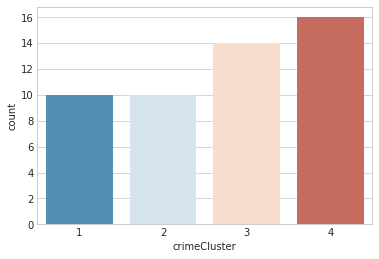

In [39]:
%matplotlib inline

sns.set_style('whitegrid')
sns.countplot(x='crimeCluster',data=crime,palette='RdBu_r')

In [42]:
%run 'graph-util/neptune.py'
%run 'graph-util/visualisation.py'

g = neptune.graphTraversal(neptune_endpoint="crime.cw8vc2udxxa2.us-east-1.neptune.amazonaws.com", 
                           neptune_port=8182)


gremlin: ws://crime.cw8vc2udxxa2.us-east-1.neptune.amazonaws.com:8182/gremlin


<Figure size 640x480 with 0 Axes>

In [43]:
user = 'Terry'

recommendations = (g.V().hasLabel('PERSON').has('name', user).as_('person').  
  both('FRIEND').aggregate('friends').  
  both('FRIEND').
    where(P.neq('person')).where(P.without('friends')).  
  groupCount().by('name').  
  order(Scope.local).by(Column.values, Order.decr).
  next())

for key in recommendations.keys():
    print(key + ': ' + str(recommendations[key]))

Henry: 3
Colin: 2
Emily: 2
Sarah: 1
Kate: 1
Chloe: 1


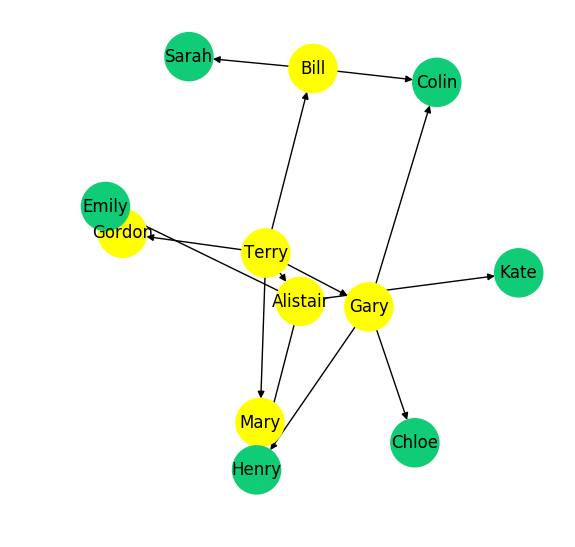

In [61]:
results = g.V().hasLabel('PERSON').has('name', user).as_('user'). \
  both('FRIEND').aggregate('friends'). \
  both('FRIEND'). \
    where(P.neq('user')).where(P.without('friends')).aggregate('not-friends').by('name'). \
  path().by('name').aggregate('p'). \
  project('not-friends', 'paths'). \
  by(__.select('not-friends').unfold().dedup().fold()). \
  by(__.select('p')).next()

notFriends = results['not-friends']
paths = results['paths']

def formatter(label, colors):
    if label in notFriends:
        colors.append('#11cc77')
    else:
        colors.append('yellow')

visualisation.plotPaths(paths, formatter)

## 2. Model Training (Entrenamiento modelo)

In [6]:
from sagemaker import KMeans
from sagemaker import get_execution_role

role = get_execution_role()
print(role)

bucket = "alexbc.datalake"

data_location = 's3://{}/kidnapping-records/model/data'.format(bucket)
output_location = 's3://{}/kidnapping-records/model/output'.format(bucket)

print('training data will be uploaded to: {}'.format(data_location))
print('training artifacts will be uploaded to: {}'.format(output_location))

kmeans = KMeans(role=role,
                train_instance_count=1,
                train_instance_type='ml.m5.xlarge',
                output_path=output_location,
                k=10,
                data_location=data_location)

arn:aws:iam::771620814942:role/service-role/AmazonSageMaker-ExecutionRole-20171212T090635
training data will be uploaded to: s3://alexbc.datalake/kidnapping-records/model/data
training artifacts will be uploaded to: s3://alexbc.datalake/kidnapping-records/model/output


In [7]:
crimeArray = crime.as_matrix().astype(np.float32)
crimeArray.shape
slice=crimeArray[:,1:5]

In [8]:
%%time
kmeans.fit(kmeans.record_set(slice))

INFO:sagemaker:Creating training-job with name: kmeans-2019-02-27-21-03-10-640


2019-02-27 21:03:10 Starting - Starting the training job...
2019-02-27 21:03:11 Starting - Launching requested ML instances......
2019-02-27 21:04:18 Starting - Preparing the instances for training......
2019-02-27 21:05:41 Downloading - Downloading input data
2019-02-27 21:05:41 Training - Downloading the training image..
Docker entrypoint called with argument(s): train
[02/27/2019 21:05:46 INFO 140220592731968] Reading default configuration from /opt/amazon/lib/python2.7/site-packages/algorithm/resources/default-input.json: {u'_tuning_objective_metric': u'', u'_num_gpus': u'auto', u'local_lloyd_num_trials': u'auto', u'_log_level': u'info', u'_kvstore': u'auto', u'local_lloyd_init_method': u'kmeans++', u'force_dense': u'true', u'epochs': u'1', u'init_method': u'random', u'local_lloyd_tol': u'0.0001', u'local_lloyd_max_iter': u'300', u'_disable_wait_to_read': u'false', u'extra_center_factor': u'auto', u'eval_metrics': u'["msd"]', u'_num_kv_servers': u'1', u'mini_batch_size': u'5000', u


2019-02-27 21:05:57 Uploading - Uploading generated training model
2019-02-27 21:05:57 Completed - Training job completed
Billable seconds: 36
CPU times: user 442 ms, sys: 29.9 ms, total: 472 ms
Wall time: 3min 12s


## 3. Model Deployment - (Mover el modelo a la producción).

In [10]:
%%time
kmeans_predictor = kmeans.deploy(initial_instance_count=1,
                                 instance_type='ml.t2.large')

INFO:sagemaker:Creating model with name: kmeans-2019-02-27-23-39-01-934
INFO:sagemaker:Creating endpoint with name kmeans-2019-02-27-21-03-10-640


ClientError: An error occurred (ValidationException) when calling the CreateEndpoint operation: Cannot create already existing endpoint "arn:aws:sagemaker:us-east-1:771620814942:endpoint/kmeans-2019-02-27-21-03-10-640".

# 99. Other examples

https://aws.amazon.com/blogs/publicsector/estimating-hurricane-wind-speeds-with-machine-learning/